<a href="https://colab.research.google.com/github/kudinha/MW1-Rotation-C-D/blob/main/Lab_Day_1_Curves.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')   # click through the authorization prompt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import t

AREA = 1.0   # cm^2, active membrane area -- REPLACE with your cell's area

Mounted at /content/drive


Load data

In [3]:
# A native Google Sheet isn't an .xlsx file on Drive, so read it with gspread.
import gspread
from google.colab import auth
from google.auth import default

auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

SHEET_NAME = "Day 1 Experiments"   # the Google Sheet's title as shown in Drive
book = gc.open(SHEET_NAME)

def load_sheet(tab):
    rows = book.worksheet(tab).get_all_values()[1:]   # skip the header row
    V, I = [], []
    for r in rows:
        # Column B = V (V), column C = I (mA); column A (R) is ignored
        if len(r) > 2 and r[1] != "" and r[2] != "":
            V.append(float(r[1]))
            I.append(float(r[2]))
    V = np.array(V) * 1000.0   # V -> mV
    i = np.array(I) / AREA     # mA -> mA/cm^2
    order = np.argsort(i)
    return i[order], V[order]

i_pem, V_pem = load_sheet("PEM Fuel Cell")   # tab names must match exactly
i_ser, V_ser = load_sheet("Series")
print(len(i_pem), "PEM points;", len(i_ser), "series points")

36 PEM points; 24 series points


Model

In [4]:
def model(i, C, B, R, w, z):
    # V = C - B*log10(i) - i*R - w*exp(z*i),  where C = E + A
    # C [mV], B [mV/decade], R [mV*cm^2/mA = ohm*cm^2], w [mV], z [cm^2/mA]
    return C - B*np.log10(i) - i*R - w*np.exp(z*i)

Parameter scales

In [5]:
# With w = 0, eqn [15] is linear in C, B, R, so it can be fit by least squares,
# the multi-variable version of LINEST / np.polyfit from the module.
def linear_scale_fit(i, V):
    X = np.column_stack([np.ones_like(i), -np.log10(i), -i])  # design matrix
    p, *_ = np.linalg.lstsq(X, V, rcond=None)
    resid = V - X @ p
    dof = len(V) - X.shape[1]
    cov = (resid @ resid / dof) * np.linalg.inv(X.T @ X)       # same as polyfit cov=True
    return p, np.sqrt(np.diag(cov))

for name, i, V in [("PEM", i_pem, V_pem), ("Series", i_ser, V_ser)]:
    p, s = linear_scale_fit(i, V)
    print(f"{name}: C = {p[0]:.0f} ± {s[0]:.0f} mV, "
          f"B = {p[1]:.1f} ± {s[1]:.1f} mV/dec, R = {p[2]:.2f} ± {s[2]:.2f}")

PEM: C = 858 ± 1 mV, B = 93.8 ± 4.0 mV/dec, R = 2.53 ± 0.19
Series: C = 1708 ± 17 mV, B = 205.5 ± 22.8 mV/dec, R = 2.45 ± 0.41


nonlinear fit of eq 15

In [6]:
def full_fit(i, V):
    p_lin, _ = linear_scale_fit(i, V)
    p0 = [p_lin[0], p_lin[1], p_lin[2], 1.0, 0.03]   # start from Step 1 values
    lower = [0, 0, 0, 0, 0]                          # all parameters physically >= 0
    upper = [5000, 1000, 100, 1e4, 1.0]
    p, cov = curve_fit(model, i, V, p0=p0, bounds=(lower, upper), maxfev=200000)
    resid = V - model(i, *p)
    r2 = 1 - np.sum(resid**2) / np.sum((V - V.mean())**2)
    return p, cov, r2

fits = {}
names = ["C", "B", "R", "w", "z"]
for name, i, V in [("PEM", i_pem, V_pem), ("Series", i_ser, V_ser)]:
    p, cov, r2 = full_fit(i, V)
    fits[name] = (p, cov)
    print(f"--- {name}  (R^2 = {r2:.4f})")
    for n, val, sd in zip(names, p, np.sqrt(np.diag(cov))):
        print(f"  {n} = {val:.4g} ± {sd:.2g}")   # sqrt of variance = stdev

--- PEM  (R^2 = 0.9929)
  C = 857.8 ± 5.2e+05
  B = 93.76 ± 4.2
  R = 2.53 ± 1.1e+03
  w = 0.002136 ± 5.2e+05
  z = 6.967e-07 ± 5.1e+05
--- Series  (R^2 = 0.9677)
  C = 1708 ± 1.3e+06
  B = 205.5 ± 40
  R = 2.45 ± 2.9e+03
  w = 0.1266 ± 1.3e+06
  z = 3.346e-06 ± 2.3e+04


performance curve with 95% band

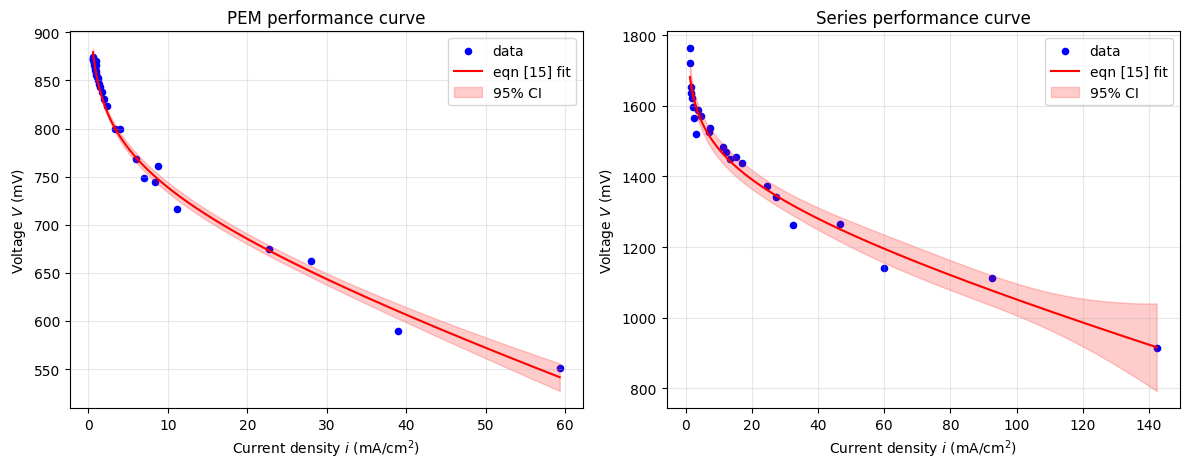

In [10]:
def conf_band(i_fit, p, cov, n_data, level=0.95):
    # Delta method: propagate the parameter covariance through the model.
    # This is the nonlinear analog of the module's confidence-band formula.
    eps = 1e-6
    J = np.array([(model(i_fit, *(p + eps*np.eye(len(p))[k])) - model(i_fit, *p)) / eps
                  for k in range(len(p))]).T
    se = np.sqrt(np.einsum("ij,jk,ik->i", J, cov, J))
    return t.ppf(0.5 + level/2, n_data - len(p)) * se   # t-score instead of 1.96 (small n)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, i, V) in zip(axes, [("PEM", i_pem, V_pem), ("Series", i_ser, V_ser)]):
    p, cov = fits[name]
    i_fit = np.linspace(i.min(), i.max(), 400)
    V_fit = model(i_fit, *p)
    band = conf_band(i_fit, p, cov, len(i))

    ax.scatter(i, V, color="b", s=20, label="data")
    ax.plot(i_fit, V_fit, "r-", label="eqn [15] fit")
    ax.fill_between(i_fit, V_fit - band, V_fit + band, color="r", alpha=0.2, label="95% CI")
    ax.set_xlabel(r"Current density $i$ (mA/cm$^2$)")
    ax.set_ylabel(r"Voltage $V$ (mV)")
    ax.set_title(f"{name} performance curve")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()